# **1. Data Visualization — Global AI Jobs 2026**

**Nama:** Apriliana Trisnawati Dau  
**NIM:** 2418054  
**Mata Kuliah:** Data Mining  

# **Pendahuluan**
Proyek ini bertujuan mengeksplorasi dataset Global AI Jobs 2026 melalui proses pengolahan data dan visualisasi. Analisis mencakup frekuensi catatan menurut spesialisasi AI, median gaji berdasarkan tingkat pengalaman, negara yang sering tercatat, ketersediaan kerja dari rumah, rata-rata gaji per spesialisasi, serta pola catatan berdasarkan waktu posting. Setiap visualisasi dilengkapi penjelasan mengenai tujuan grafik, cara membacanya, dan batasan interpretasi agar hasil tidak disimpulkan melebihi informasi yang tersedia dalam dataset.

> **Catatan interpretasi:** hasil hanya menggambarkan pola pada file yang dianalisis. Jangan menganggapnya otomatis mewakili seluruh pasar kerja AI dunia. Periksa dokumentasi dan sumber dataset sebelum membuat klaim faktual tentang pasar kerja.

# **2. Import library**
Bagian ini memanggil pustaka Python yang dibutuhkan selama analisis. Pandas digunakan untuk membaca, memilih, mengelompokkan, dan merangkum data dalam bentuk tabel. Matplotlib menyediakan fungsi dasar untuk membuat grafik, sedangkan Seaborn membantu menghasilkan visualisasi statistik dengan format yang lebih ringkas dan rapi.
Library perlu diimpor sebelum digunakan pada sel berikutnya. Jika sel ini belum dijalankan, kode pengolahan data maupun grafik dapat menghasilkan pesan error karena fungsi yang diperlukan belum dikenali.

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import files

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

# **3. Memuat dataset**
Pada tahap ini, file global_ai_jobs_2026_cleaned.csv dibaca ke dalam DataFrame Pandas agar dapat diperiksa dan dianalisis menggunakan Python. Pastikan file yang diunggah benar dan nama filenya sesuai dengan yang digunakan dalam kode. Jika file sudah tersedia di direktori kerja Google Colab, kode dapat membacanya langsung.
Setelah dataset berhasil dimuat, periksa beberapa baris awal dan ukuran data untuk memastikan proses pembacaan berhasil. Jumlah baris menunjukkan banyaknya catatan yang tersedia, sedangkan jumlah kolom menunjukkan banyaknya atribut yang dapat digunakan untuk analisis. Tahap ini belum mengubah isi data.

In [45]:
from google.colab import drive
from pathlib import Path

# Hubungkan Google Drive ke Google Colab
drive.mount('/content/drive')

# Lokasi dataset di Google Drive
file_path = '/content/drive/MyDrive/Colab Notebooks/dataset/global_ai_jobs_2026_cleaned.csv'

# Baca dataset
df = pd.read_csv(file_path)

# Tampilkan informasi dataset
print(f"Jumlah baris: {df.shape[0]:,}")
print(f"Jumlah kolom: {df.shape[1]}")

# Tampilkan 5 baris pertama
display(df.head())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Jumlah baris: 5,000
Jumlah kolom: 37


,Job_ID,Job_Title,AI_Specialization,Industry,Company,Company_Size,Country,Continent,Education_Required,Experience_Level,...,Work_Life_Balance_1_10,AI_Investment_Company_Millions,Company_AI_Maturity_1_10,Job_Growth_Projection_%,Automation_Risk_%,Gender_Diversity_%_Female,Posted_Date,Application_Deadline,Record_Created,Data_Source
0,AI-03546,Business Intelligence Analyst,Computer Vision,E-commerce,Alibaba,Enterprise (5000+),Israel,Asia,Bachelor's,Executive,...,5.2,39,3.9,30.7,10.2,22.7,2035-09-16,2035-10-17,2026-08-28,Global AI Jobs Report 2026
1,AI-01969,Generative AI Engineer,Reinforcement Learning,Automotive,UiPath,Large (501-5000),United States,North America,Master's,Executive,...,7.3,499,3.9,18.1,20.7,39.8,2031-05-23,2031-06-23,2026-08-28,Global AI Jobs Report 2026
2,AI-02960,AI Software Engineer,Deep Learning,Insurance,UiPath,Enterprise (5000+),United States,North America,Postdoctoral,Executive,...,5.5,5,2.8,43.7,29.1,27.1,2034-02-07,2034-03-10,2026-08-28,Global AI Jobs Report 2026
3,AI-02384,NLP Engineer,Other,Transportation,Adobe,Large (501-5000),United States,North America,PhD,Executive,...,4.7,172,8.1,39.9,24.9,15.9,2032-07-11,2032-08-11,2026-08-28,Global AI Jobs Report 2026
4,AI-03930,AI Solutions Architect,Reinforcement Learning,Cloud Computing,Megvii,Large (501-5000),Switzerland,Europe,PhD,Executive,...,8.1,65,6.8,25.6,31.5,41.2,2036-10-04,2036-11-04,2026-08-28,Global AI Jobs Report 2026


# **4. Memahami struktur data**
Sebelum membuat grafik, struktur dataset perlu dipahami terlebih dahulu. Pemeriksaan tipe data membantu mengetahui apakah kolom dibaca sebagai teks, angka, atau tanggal. Ringkasan statistik memberi gambaran awal tentang nilai numerik, misalnya sebaran gaji, sedangkan pemeriksaan nilai kosong dan duplikasi membantu menilai kelengkapan serta kemungkinan catatan berulang.
Informasi ini penting karena format yang keliru dapat memengaruhi hasil perhitungan. Sebagai contoh, gaji yang terbaca sebagai teks tidak dapat langsung dihitung rata-ratanya, dan tanggal yang belum dikonversi mungkin tidak dapat dikelompokkan berdasarkan tahun dengan benar. Gunakan hasil pemeriksaan sebagai dasar untuk menentukan pembersihan yang diperlukan.

In [46]:
print("Informasi dataset:")
df.info()

print("\\nJumlah nilai kosong per kolom (hanya kolom yang memiliki nilai kosong):")
missing = df.isna().sum()
display(missing[missing > 0].sort_values(ascending=False).to_frame("Jumlah_Nilai_Kosong"))

print(f"\\nJumlah baris duplikat: {df.duplicated().sum():,}")

print("\\nRingkasan statistik kolom numerik:")
display(df.describe().T)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 37 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Job_ID                          5000 non-null   object 
 1   Job_Title                       5000 non-null   object 
 2   AI_Specialization               5000 non-null   object 
 3   Industry                        5000 non-null   object 
 4   Company                         5000 non-null   object 
 5   Company_Size                    5000 non-null   object 
 6   Country                         5000 non-null   object 
 7   Continent                       5000 non-null   object 
 8   Education_Required              5000 non-null   object 
 9   Experience_Level                5000 non-null   object 
 10  Years_of_Experience             5000 non-null   int64  
 11  Salary_USD                      5000 non-null   float64
 12  Salary_Min     

,Jumlah_Nilai_Kosong


\nJumlah baris duplikat: 0
\nRingkasan statistik kolom numerik:


,count,mean,std,min,25%,50%,75%,max
Years_of_Experience,5000.0,7.57540,6.245263,0.0,2.00,7.00,12.000,20.0
Salary_USD,5000.0,158179.95840,78886.439234,27934.0,104261.25,141886.00,191695.000,718357.0
Salary_Min,5000.0,126656.83140,63920.017903,21398.0,83105.50,113983.00,154688.500,614788.0
Salary_Max,5000.0,197920.70540,100139.163004,34852.0,129468.00,176796.00,239955.750,917269.0
Bonus_%,5000.0,17.33884,7.238298,5.0,10.90,17.40,23.600,30.0
Benefits_Value_USD,5000.0,22363.49640,10110.624917,5002.0,13607.75,22412.00,31134.250,39989.0
Job_Openings,5000.0,10.07360,3.210209,1.0,8.00,10.00,12.000,22.0
Competition_Level_Applicants,5000.0,257.89520,141.564460,10.0,134.00,259.00,381.000,500.0
Hiring_Difficulty_1_10,5000.0,6.30412,1.884440,3.0,4.70,6.30,7.900,9.5
Remote_Work_%,5000.0,57.74800,26.115606,0.0,40.00,60.00,80.000,100.0


# **5. Pembersihan data**
Pembersihan dilakukan untuk menyiapkan data agar lebih konsisten saat dianalisis. Kode membuat salinan dataset, menghapus spasi yang tidak diperlukan pada nilai teks, mengonversi kolom tanggal ke format tanggal, serta memastikan kolom gaji dapat diproses sebagai nilai numerik.
Nilai yang tidak dapat dikonversi menjadi tanggal atau angka dapat berubah menjadi nilai kosong, sehingga perlu diperhatikan ketika menghitung statistik. Data kosong pada satu kolom tidak selalu berarti seluruh baris harus dihapus: apabila kolom lain masih memiliki informasi yang berguna, baris tersebut tetap dapat dipakai untuk analisis yang relevan. Karena itu, setiap visualisasi sebaiknya menggunakan kolom yang dibutuhkan dan mengabaikan nilai yang tidak valid hanya untuk perhitungan tersebut.

In [47]:
data = df.copy()

# Rapikan spasi pada kolom teks
text_cols = data.select_dtypes(include="object").columns
for col in text_cols:
    data[col] = data[col].apply(lambda x: x.strip() if isinstance(x, str) else x)

# Konversi kolom tanggal bila tersedia
for col in ["Posted_Date", "Application_Deadline", "Record_Created"]:
    if col in data.columns:
        data[col] = pd.to_datetime(data[col], errors="coerce")

# Pastikan kolom gaji numerik
for col in ["Salary_USD", "Salary_Min", "Salary_Max"]:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Untuk analisis sertifikasi, nilai kosong dapat ditampilkan sebagai "Tidak dicantumkan"
if "Required_Certifications" in data.columns:
    data["Required_Certifications"] = data["Required_Certifications"].fillna("Tidak dicantumkan")

print("Ukuran data setelah pembersihan ringan:", data.shape)
print("Jumlah nilai kosong pada Salary_USD:", data["Salary_USD"].isna().sum() if "Salary_USD" in data.columns else "Kolom tidak ditemukan")

Ukuran data setelah pembersihan ringan: (5000, 37)
Jumlah nilai kosong pada Salary_USD: 0


# **6. Visualisasi 1 — Jumlah catatan berdasarkan spesialisasi AI**
Grafik batang ini menunjukkan berapa banyak baris dataset yang tercatat pada setiap kategori AI_Specialization. Setiap batang mewakili satu spesialisasi AI, dan tinggi batang menunjukkan jumlah catatan untuk kategori tersebut. Grafik ini berguna untuk melihat kategori yang paling sering maupun paling jarang muncul serta membandingkan ukuran tiap kategori dengan cepat.
Perlu dibedakan antara jumlah catatan dan jumlah posisi yang dibuka. Satu baris dataset belum tentu sama dengan satu posisi pekerjaan; jika tujuan analisisnya adalah menghitung total posisi, kolom Job_Openings perlu dijumlahkan secara terpisah. Oleh karena itu, grafik ini secara khusus menggambarkan frekuensi catatan dalam file.

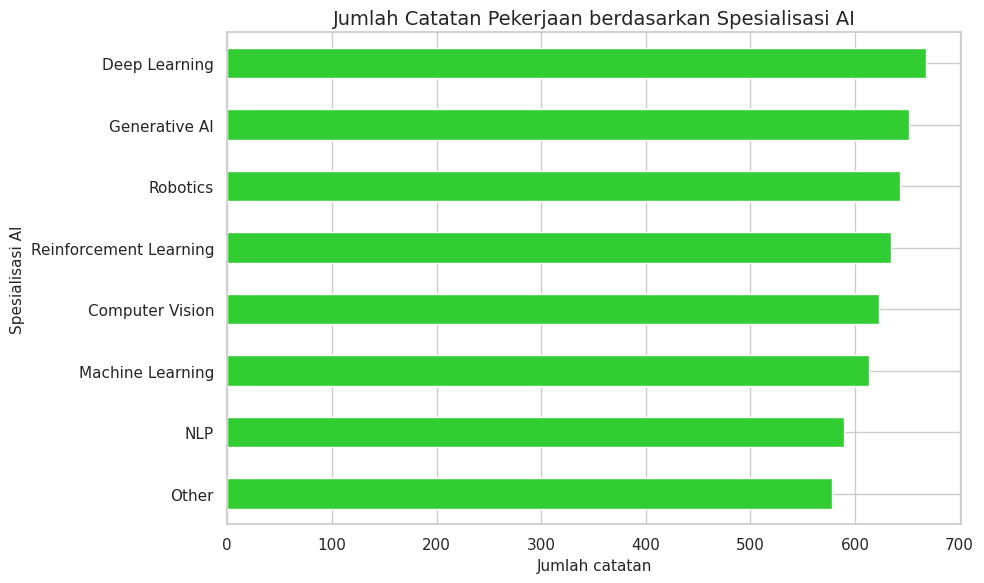

In [48]:
if "AI_Specialization" in data.columns:
    specialization_counts = data["AI_Specialization"].value_counts().sort_values()
    ax = specialization_counts.plot(kind="barh", color="limegreen")
    ax.set_title("Jumlah Catatan Pekerjaan berdasarkan Spesialisasi AI")
    ax.set_xlabel("Jumlah catatan")
    ax.set_ylabel("Spesialisasi AI")
    plt.tight_layout()
    plt.show()
else:
    print("Kolom AI_Specialization tidak ditemukan.")

**Interpretasi:** cari batang yang paling tinggi dan paling rendah, lalu sebutkan kategori serta nilainya berdasarkan grafik atau tabel hasil. Jelaskan apakah catatan terkonsentrasi pada beberapa spesialisasi atau tersebar relatif merata. Hindari menyimpulkan bahwa spesialisasi dengan catatan terbanyak pasti memiliki permintaan global tertinggi, karena hasil ini hanya mencerminkan data yang tersedia dalam dataset.

# **7. Visualisasi 2 — Median gaji berdasarkan tingkat pengalaman**
Grafik batang ini membandingkan median gaji untuk setiap tingkat pengalaman kerja. Median adalah nilai tengah setelah gaji diurutkan, sehingga biasanya tidak terlalu mudah berubah akibat beberapa nilai gaji yang sangat tinggi atau sangat rendah dibandingkan rata-rata.
Grafik ini membantu melihat bagaimana nilai tengah gaji berbeda antara level pengalaman yang tersedia dalam dataset. Perhitungan hanya menggunakan baris dengan nilai gaji numerik yang valid. Pastikan satuan gaji yang tercatat dipahami dengan benar sebelum menafsirkan besarnya nilai, terutama jika dataset memuat perbedaan negara atau mata uang.

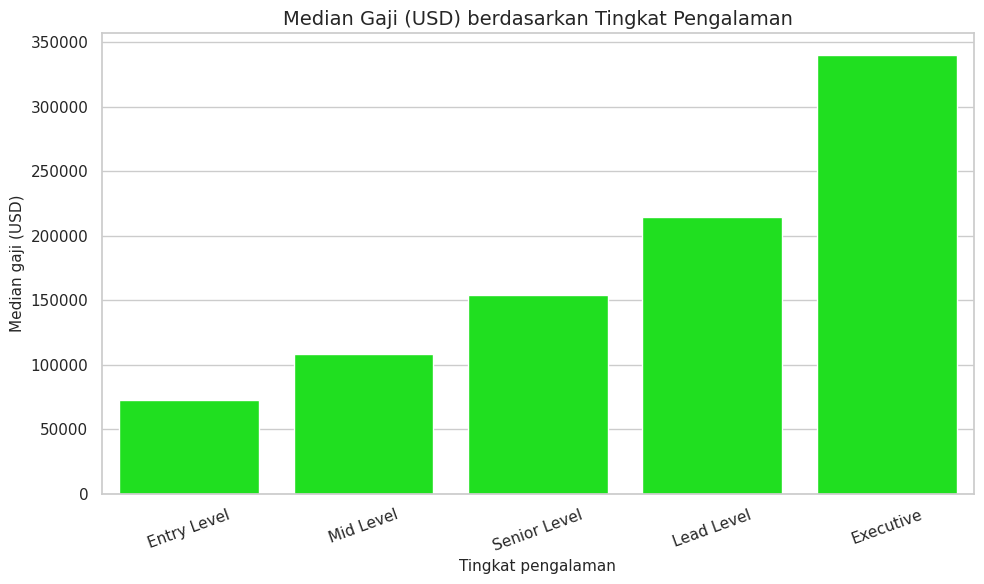

,Median_Gaji_USD
Experience_Level,
Executive,339774.0
Lead Level,214833.0
Senior Level,154104.5
Mid Level,108376.0
Entry Level,72536.0


In [49]:
required = {"Experience_Level", "Salary_USD"}
if required.issubset(data.columns):
    salary_data = data.dropna(subset=["Experience_Level", "Salary_USD"])
    salary_order = salary_data.groupby("Experience_Level")["Salary_USD"].median().sort_values().index
    ax = sns.barplot(
        data=salary_data,
        x="Experience_Level",
        y="Salary_USD",
        order=salary_order,
        estimator="median",
        errorbar=None,
        color="lime"
    )
    ax.set_title("Median Gaji (USD) berdasarkan Tingkat Pengalaman")
    ax.set_xlabel("Tingkat pengalaman")
    ax.set_ylabel("Median gaji (USD)")
    ax.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    plt.show()

    display(salary_data.groupby("Experience_Level")["Salary_USD"].median()
            .sort_values(ascending=False).rename("Median_Gaji_USD").to_frame())
else:
    print("Kolom Experience_Level dan/atau Salary_USD tidak ditemukan.")

**Interpretasi:** bandingkan tinggi batang antarlevel pengalaman. Batang tertinggi menunjukkan level dengan median gaji terbesar pada data yang dianalisis, sedangkan batang terendah menunjukkan median terkecil. Sebutkan pola yang benar-benar tampak pada grafik. Perbedaan ini tidak membuktikan bahwa pengalaman merupakan satu-satunya penyebab perbedaan gaji karena lokasi, spesialisasi, jenis pekerjaan, dan faktor lain juga mungkin berpengaruh.

# **8. Visualisasi 3 — 10 Negara dengan Jumlah Lowongan Kerja AI Terbanyak**
Grafik batang horizontal ini menampilkan sepuluh negara dengan jumlah catatan lowongan kerja AI terbanyak dalam dataset. Jumlah dihitung berdasarkan banyaknya baris data pada kolom Country, kemudian diurutkan untuk memudahkan perbandingan antarnegara. Grafik ini membantu menunjukkan negara mana yang paling banyak terwakili dalam dataset. Perlu diperhatikan bahwa jumlah tersebut bukan total posisi yang tersedia berdasarkan kolom Job_Openings, dan tidak secara langsung menggambarkan jumlah seluruh lowongan kerja AI di dunia karena hasilnya bergantung pada cakupan dataset yang digunakan.

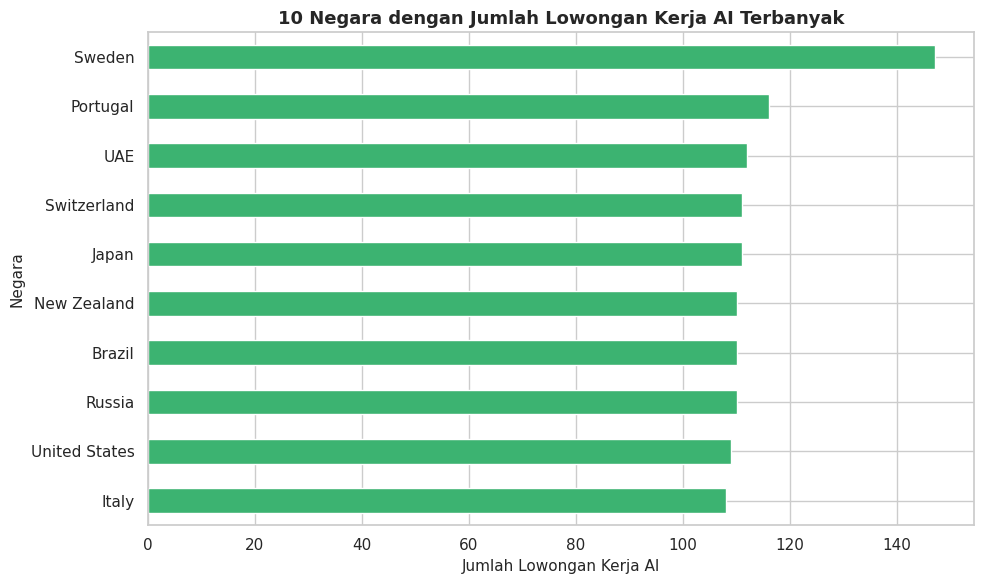

,Jumlah Lowongan
Country,
Sweden,147
Portugal,116
UAE,112
Japan,111
Switzerland,111
New Zealand,110
Russia,110
Brazil,110
United States,109


In [60]:

if "Country" in data.columns:
    country_counts = (
        data["Country"]
        .value_counts()
        .head(10)
        .sort_values()
    )

    ax = country_counts.plot(
        kind="barh",
        figsize=(10, 6),
        color="mediumseagreen"
    )

    ax.set_title(
        "10 Negara dengan Jumlah Lowongan Kerja AI Terbanyak",
        fontsize=13,
        fontweight="bold"
    )
    ax.set_xlabel("Jumlah Lowongan Kerja AI")
    ax.set_ylabel("Negara")

    plt.tight_layout()
    plt.show()

    display(
        data["Country"]
        .value_counts()
        .head(10)
        .rename("Jumlah Lowongan")
        .to_frame()
    )

else:
    print("Kolom Country tidak ditemukan.")


# **9. Visualisasi 4 — Ketersediaan kerja dari rumah**
Grafik ini membandingkan banyaknya catatan pada setiap kategori di kolom Work_From_Home_Available. Kategori dapat berupa “Yes”, “No”, atau nilai lain sesuai isi dataset. Sebelum menafsirkan grafik, periksa label kategori yang benar-benar muncul agar tidak mengasumsikan bahwa hanya ada dua pilihan.
Visualisasi ini memberi gambaran apakah catatan yang menyebut opsi kerja dari rumah lebih banyak atau lebih sedikit dibandingkan kategori lainnya. Namun, grafik tidak menjelaskan apakah pekerjaan tersebut sepenuhnya jarak jauh, hybrid, atau memiliki ketentuan khusus kecuali informasi tersebut memang dijelaskan oleh kolom dalam dataset.

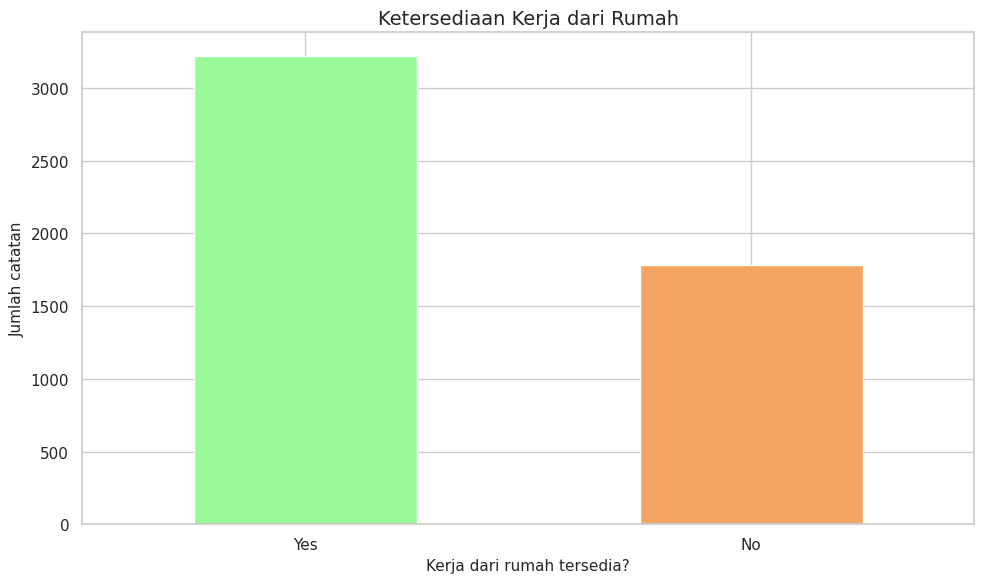

,Jumlah_Catatan
Work_From_Home_Available,
Yes,3221
No,1779


In [51]:
if "Work_From_Home_Available" in data.columns:
    remote_counts = data["Work_From_Home_Available"].fillna("Tidak diketahui").value_counts()
    ax = remote_counts.plot(kind="bar", color=["palegreen", "sandybrown", "gray", "teal"][:len(remote_counts)])
    ax.set_title("Ketersediaan Kerja dari Rumah")
    ax.set_xlabel("Kerja dari rumah tersedia?")
    ax.set_ylabel("Jumlah catatan")
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()
    display(remote_counts.rename("Jumlah_Catatan").to_frame())
else:
    print("Kolom Work_From_Home_Available tidak ditemukan.")

**Interpretasi:** bandingkan jumlah catatan dengan opsi kerja dari rumah “Yes” dan “No” (atau kategori lain jika ada). Grafik ini menunjukkan komposisi pada dataset, bukan kebijakan semua perusahaan.

# **10. Visualisasi 5 — Tren Jumlah Catatan Pekerjaan AI Berdasarkan Tahun**

Grafik garis ini mengelompokkan catatan berdasarkan tahun pada kolom Posted_Date. Sumbu horizontal menunjukkan tahun posting dan sumbu vertikal menunjukkan jumlah catatan yang ditemukan pada masing-masing tahun. Garis memudahkan pembaca melihat perubahan jumlah catatan dari satu tahun ke tahun berikutnya.
Grafik ini menjawab pertanyaan tentang bagaimana catatan dalam file tersebar menurut waktu, bukan tentang gaji atau jumlah posisi yang dibuka. Pastikan tanggal sudah dikonversi ke format tanggal dan periksa rentang waktunya; nama dataset yang menyebut tahun 2026 tidak otomatis berarti semua tanggal di dalam file berasal dari tahun tersebut.


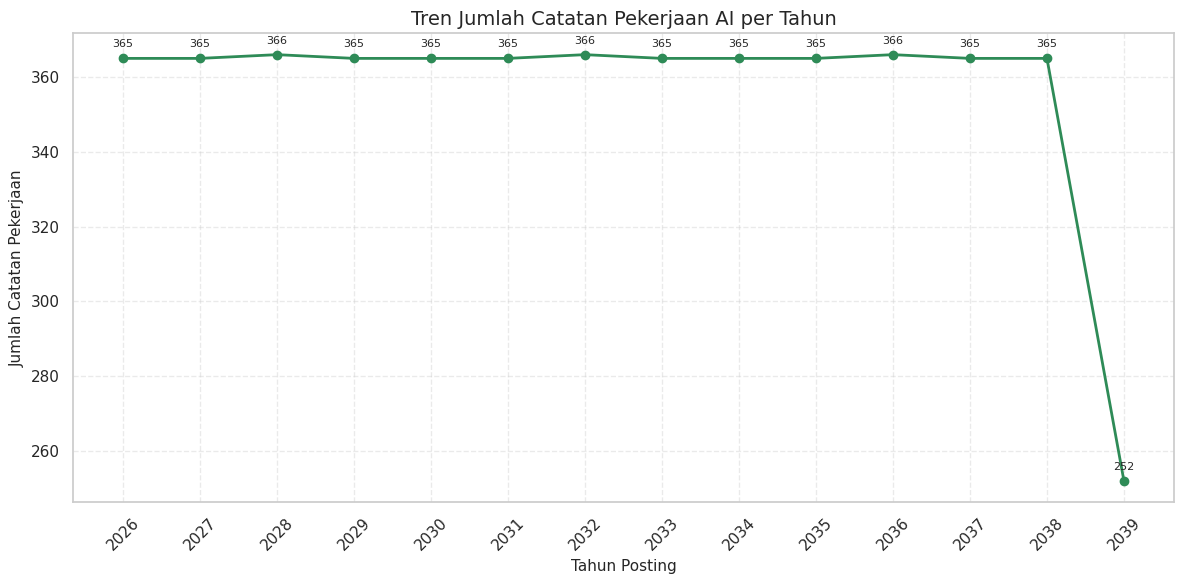

,Jumlah Catatan
Posted_Date,
2026,365
2027,365
2028,366
2029,365
2030,365
2031,365
2032,366
2033,365
2034,365


In [52]:
# VISUALISASI 5: Tren Catatan Pekerjaan AI per Tahun

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan tanggal valid
data['Posted_Date'] = pd.to_datetime(
    data['Posted_Date'], errors='coerce'
)

date_data = data.dropna(subset=['Posted_Date']).copy()

# Hitung jumlah catatan per tahun
yearly_jobs = (
    date_data.groupby(date_data['Posted_Date'].dt.year)
    .size()
    .sort_index()
)

# Buat grafik
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_jobs.index,
    yearly_jobs.values,
    marker='o',
    markersize=6,
    linewidth=2,
    color='seagreen'
)

# Tampilkan angka di setiap titik
for year, count in yearly_jobs.items():
    plt.annotate(
        str(count),
        (year, count),
        textcoords='offset points',
        xytext=(0, 8),
        ha='center',
        fontsize=8
    )

plt.title('Tren Jumlah Catatan Pekerjaan AI per Tahun')
plt.xlabel('Tahun Posting')
plt.ylabel('Jumlah Catatan Pekerjaan')
plt.xticks(yearly_jobs.index, rotation=45)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

display(yearly_jobs.rename('Jumlah Catatan').to_frame())


**Interpretasi:** Grafik garis menunjukkan jumlah catatan pekerjaan AI berdasarkan tahun posting. Sumbu X menunjukkan tahun posting, sedangkan sumbu Y menunjukkan jumlah catatan pekerjaan pada setiap tahun.

Grafik dapat digunakan untuk melihat perubahan jumlah catatan dari tahun ke tahun. Jika garis meningkat, jumlah catatan pada tahun tersebut lebih banyak dibandingkan tahun sebelumnya. Sebaliknya, jika garis menurun, jumlah catatan lebih sedikit.

Hasil visualisasi ini menggambarkan distribusi data pada dataset yang digunakan dan tidak secara langsung membuktikan tren pasar kerja AI secara global.


# **11. Visualisasi 6 — Rata-rata Gaji berdasarkan Spesialisasi AI**
Grafik batang ini membandingkan rata-rata gaji (Salary_USD) pada setiap spesialisasi AI. Untuk setiap kategori, nilai gaji numerik yang valid diringkas menggunakan rata-rata, kemudian ditampilkan sebagai tinggi batang. Grafik ini dapat membantu menemukan spesialisasi yang memiliki rata-rata gaji relatif tinggi atau rendah dalam dataset.
Rata-rata memperhitungkan seluruh nilai, sehingga dapat berubah cukup besar jika terdapat beberapa gaji ekstrem. Karena itu, hasilnya sebaiknya dibandingkan dengan median pada Visualisasi 2 dan dibaca dengan mempertimbangkan jumlah catatan pada tiap spesialisasi. Perbedaan jumlah data antar kategori dapat memengaruhi seberapa representatif nilai rata-ratanya.

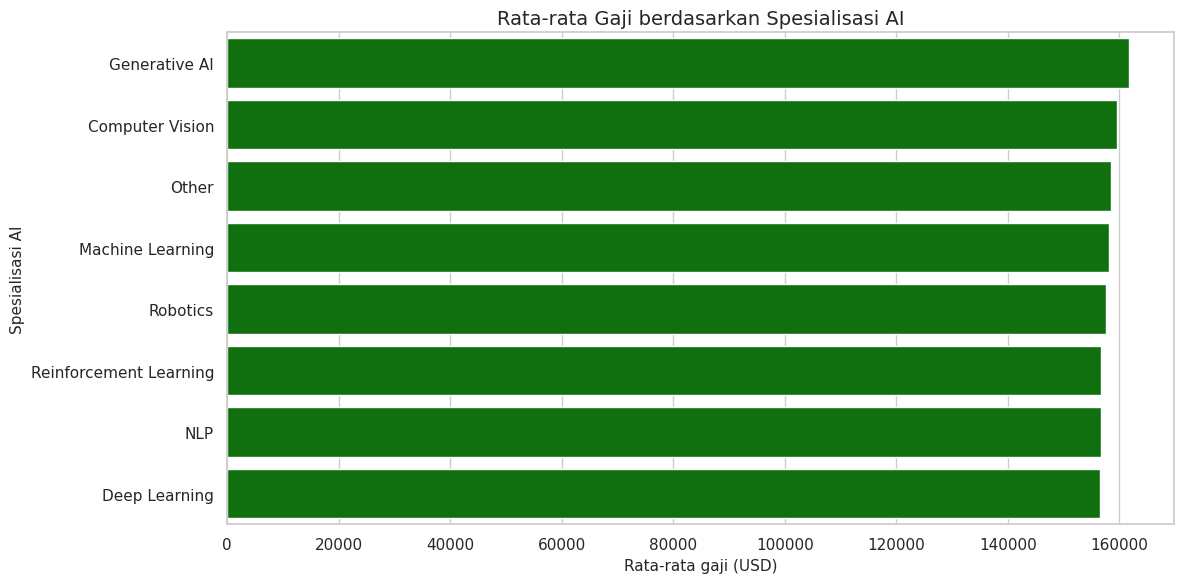

,Spesialisasi_AI,Rata_Rata_Gaji_USD
2,Generative AI,161711.176380
0,Computer Vision,159510.462279
5,Other,158486.128028
3,Machine Learning,158096.298532
7,Robotics,157632.421462
6,Reinforcement Learning,156672.299685
4,NLP,156656.500849
1,Deep Learning,156605.553892


In [53]:

required = {"AI_Specialization", "Salary_USD"}

if required.issubset(data.columns):
    salary_by_ai = (
        data.dropna(subset=["AI_Specialization", "Salary_USD"])
        .groupby("AI_Specialization", as_index=False)["Salary_USD"]
        .mean()
        .sort_values("Salary_USD", ascending=False)
    )

    plt.figure(figsize=(12, 6))
    ax = sns.barplot(data=salary_by_ai, x="Salary_USD", y="AI_Specialization", color="green")
    ax.set_title("Rata-rata Gaji berdasarkan Spesialisasi AI")
    ax.set_xlabel("Rata-rata gaji (USD)")
    ax.set_ylabel("Spesialisasi AI")
    plt.tight_layout()
    plt.show()

    display(salary_by_ai.rename(columns={
        "AI_Specialization": "Spesialisasi_AI",
        "Salary_USD": "Rata_Rata_Gaji_USD"
    }))
else:
    print("Kolom AI_Specialization dan/atau Salary_USD tidak ditemukan.")


**Interpretasi**: batang paling tinggi menunjukkan spesialisasi dengan rata-rata gaji terbesar di antara kategori yang ditampilkan, sedangkan batang paling rendah menunjukkan rata-rata terkecil. Sebutkan pola berdasarkan hasil aktual dan perhatikan kemungkinan nilai ekstrem. Jangan menganggap rata-rata tersebut sebagai gaji pasti setiap pekerja atau sebagai bukti bahwa spesialisasi itu selalu membayar lebih tinggi di semua negara dan perusahaan.

# **12. Visualisasi 7 — Distribusi Lowongan berdasarkan Tingkat Pengalaman**
Diagram lingkaran (pie chart) menunjukkan proporsi catatan berdasarkan kategori tingkat pengalaman kerja yang tersedia pada dataset. Setiap irisan mewakili satu kategori, sedangkan besar irisan dan persentasenya menunjukkan bagian kategori tersebut dari keseluruhan catatan yang masuk dalam perhitungan.
Diagram ini sesuai untuk melihat komposisi kategori secara sekilas, terutama ketika jumlah kategorinya tidak terlalu banyak. Persentase setiap irisan dihitung terhadap total catatan yang digunakan pada grafik. Kategori yang tidak memiliki nilai atau tidak muncul dalam data yang dianalisis tidak akan menjadi irisan tersendiri.

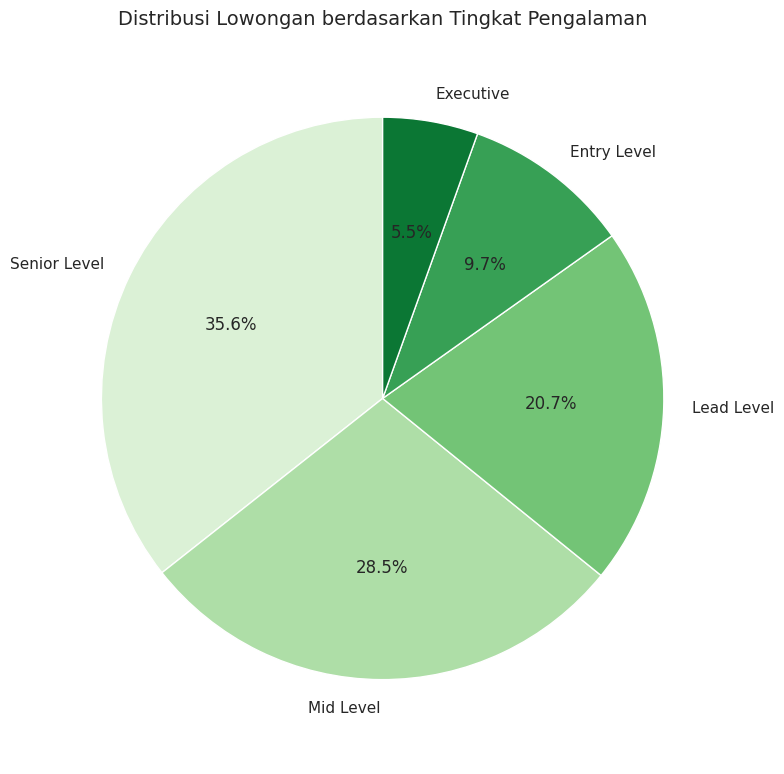

In [54]:
if "Experience_Level" in data.columns:
    experience_counts = data["Experience_Level"].dropna().value_counts()

    plt.figure(figsize=(8, 8))
    plt.pie(
        experience_counts,
        labels=experience_counts.index,
        autopct="%1.1f%%",
        startangle=90,
        colors=sns.color_palette("Greens", n_colors=len(experience_counts)),
        wedgeprops={"edgecolor": "white", "linewidth": 1}
    )
    plt.title("Distribusi Lowongan berdasarkan Tingkat Pengalaman")
    plt.axis("equal")
    plt.tight_layout()
    plt.show()
else:
    print("Kolom Experience_Level tidak ditemukan.")



**interpretasi**: irisan terbesar menunjukkan kategori tingkat pengalaman yang memiliki proporsi catatan paling besar; irisan terkecil menunjukkan proporsi paling kecil. Gunakan label dan persentase yang tertera pada grafik untuk menyampaikan temuan. Proporsi tersebut menunjukkan komposisi dataset, bukan jumlah aktual semua lowongan di dunia kerja, dan bukan pula bukti bahwa perusahaan secara umum lebih membutuhkan level tersebut.

# **13. Visualisasi 8 — Tren Jumlah Lowongan AI berdasarkan Tahun**
Grafik garis ini membandingkan jumlah catatan dari tiga spesialisasi AI yang paling sering muncul dalam dataset sepanjang tahun posting yang tersedia. Setiap garis mewakili satu spesialisasi, sumbu X menunjukkan tahun berdasarkan Posted_Date, dan sumbu Y menunjukkan jumlah catatan untuk spesialisasi tersebut pada tahun terkait.
Dibandingkan grafik tren keseluruhan pada Visualisasi 5, grafik ini memungkinkan pembaca melihat apakah pola waktu pada spesialisasi yang berbeda bergerak serupa atau berbeda. Grafik hanya menampilkan tiga spesialisasi teratas sesuai pemilihan pada kode, sehingga tidak mewakili seluruh kategori yang ada di dataset.

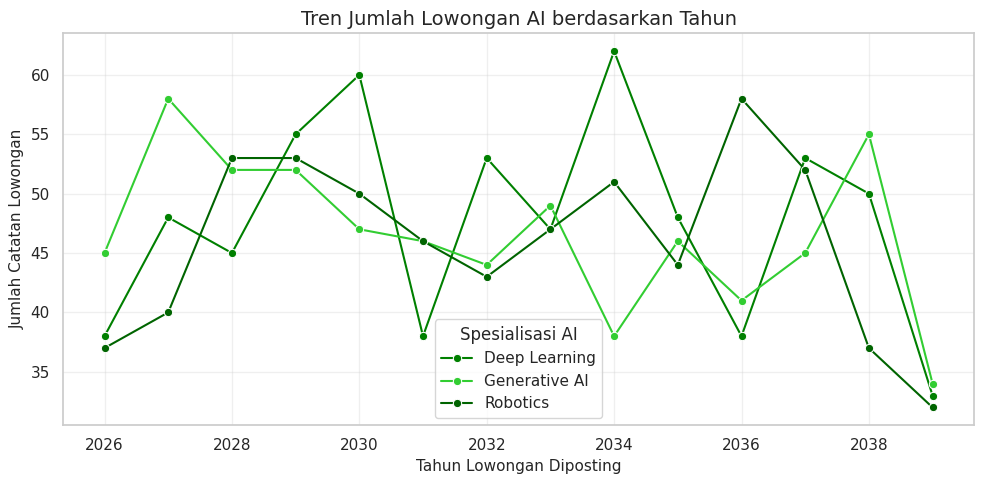

,Tahun,AI_Specialization,Jumlah_Lowongan
0,2026,Deep Learning,38
1,2026,Generative AI,45
2,2026,Robotics,37
3,2027,Deep Learning,48
4,2027,Generative AI,58
5,2027,Robotics,40
6,2028,Deep Learning,45
7,2028,Generative AI,52
8,2028,Robotics,53
9,2029,Deep Learning,55


In [62]:
# Ambil tiga spesialisasi AI dengan jumlah catatan terbanyak
top_specializations = data["AI_Specialization"].dropna().value_counts().head(3).index

trend_data = data.copy()
trend_data["Posted_Date"] = pd.to_datetime(trend_data["Posted_Date"], errors="coerce")
trend_data = trend_data.dropna(subset=["Posted_Date", "AI_Specialization"])
trend_data["Tahun"] = trend_data["Posted_Date"].dt.year

trend_data = trend_data[trend_data["AI_Specialization"].isin(top_specializations)]
yearly_trend = (
    trend_data.groupby(["Tahun", "AI_Specialization"])
    .size()
    .reset_index(name="Jumlah_Lowongan")
)

plt.figure(figsize=(10, 5))
ax = sns.lineplot(
    data=yearly_trend,
    x="Tahun",
    y="Jumlah_Lowongan",
    hue="AI_Specialization",
    marker="o",
    palette=["green", "limegreen", "darkgreen"]
)
ax.set_title("Tren Jumlah Lowongan AI berdasarkan Tahun")
ax.set_xlabel("Tahun Lowongan Diposting")
ax.set_ylabel("Jumlah Catatan Lowongan")
ax.legend(title="Spesialisasi AI")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(yearly_trend)


**Interpretasi** : cocokkan setiap warna garis dengan legenda untuk mengetahui spesialisasinya. Garis yang naik menunjukkan jumlah catatan spesialisasi itu lebih tinggi pada tahun berikutnya, sedangkan garis yang turun menunjukkan jumlah lebih rendah. Bandingkan garis untuk melihat spesialisasi mana yang memiliki catatan paling banyak pada tahun tertentu dan apakah pola mereka berubah. Interpretasi tetap dibatasi pada catatan dalam dataset; grafik tidak otomatis mewakili seluruh pasar kerja AI.

# **14. Pemeriksaan tanggal dan nilai gaji ekstrem**
ahap ini memeriksa rentang tanggal posting dan meninjau nilai gaji yang sangat jauh dari sebagian besar data. Pemeriksaan tanggal penting untuk memastikan periode yang dianalisis sesuai dengan isi dataset. Walaupun nama dataset mengandung tahun 2026, data mungkin mencakup tanggal dari tahun lain; hal ini perlu dijelaskan jika memengaruhi interpretasi grafik tren.
# Nilai gaji ekstrem juga perlu ditinjau untuk mengetahui apakah nilainya masuk akal, berasal dari format yang salah, atau memang menggambarkan kondisi khusus. Nilai ekstrem tidak sebaiknya langsung dihapus hanya karena berbeda jauh. Keputusan pembersihan harus didasarkan pada pemeriksaan yang masuk akal dan dicatat agar proses analisis transparan.

In [63]:
if "Posted_Date" in data.columns:
    print("Rentang Posted_Date:", data["Posted_Date"].min(), "sampai", data["Posted_Date"].max())
    print("\\nJumlah catatan berdasarkan tahun posting:")
    display(data["Posted_Date"].dt.year.value_counts(dropna=True).sort_index().rename("Jumlah_Catatan").to_frame())

if "Salary_USD" in data.columns:
    print("\\nRingkasan Salary_USD:")
    display(data["Salary_USD"].describe().to_frame("Salary_USD"))
    print("Persentil 99 gaji:", data["Salary_USD"].quantile(0.99))

Rentang Posted_Date: 2026-01-01 00:00:00 sampai 2039-09-09 00:00:00
\nJumlah catatan berdasarkan tahun posting:


,Jumlah_Catatan
Posted_Date,
2026,365
2027,365
2028,366
2029,365
2030,365
2031,365
2032,366
2033,365
2034,365


\nRingkasan Salary_USD:


,Salary_USD
count,5000.000000
mean,158179.958400
std,78886.439234
min,27934.000000
25%,104261.250000
50%,141886.000000
75%,191695.000000
max,718357.000000


Persentil 99 gaji: 436004.1800000006


# **15. Kesimpulan**

Berdasarkan hasil analisis dan visualisasi dataset *Global AI Jobs 2026*, dapat ditarik beberapa kesimpulan sebagai berikut:

1. Spesialisasi AI yang paling sering tercatat dalam dataset adalah spesialisasi dengan jumlah kemunculan tertinggi pada Visualisasi 1. Hasil ini menunjukkan spesialisasi yang paling banyak terwakili dalam data lowongan kerja AI.

2. Tingkat pengalaman kerja dengan median gaji tertinggi berdasarkan Visualisasi 2 menunjukkan kelompok pengalaman yang memiliki nilai tengah gaji paling besar dalam dataset.

3. Berdasarkan Visualisasi 3, negara dengan jumlah catatan lowongan kerja AI terbanyak merupakan negara yang paling banyak terwakili dalam dataset. Hasil ini menggambarkan persebaran catatan berdasarkan negara, bukan jumlah seluruh lowongan kerja AI di dunia.

4. Visualisasi 4 menunjukkan perbandingan ketersediaan kerja dari rumah berdasarkan kategori yang tercatat. Hasil tersebut membantu memahami apakah kategori kerja dari rumah atau tidak kerja dari rumah lebih banyak muncul dalam dataset.

5. Berdasarkan Visualisasi 5, pola jumlah catatan pekerjaan AI dari waktu ke waktu dapat diamati melalui grafik garis. Pola tersebut menunjukkan perubahan jumlah catatan pada periode yang tercakup dalam dataset.

Secara keseluruhan, visualisasi membantu memahami distribusi spesialisasi AI, perbandingan gaji berdasarkan tingkat pengalaman, persebaran catatan pekerjaan antarnegara, ketersediaan kerja dari rumah, serta perubahan jumlah catatan berdasarkan waktu. Analisis ini memberikan gambaran awal mengenai karakteristik data lowongan kerja AI dalam dataset *Global AI Jobs 2026*.

**Keterbatasan:** hasil analisis bergantung pada kualitas, cakupan, dan kelengkapan dataset. Rentang tanggal, nilai gaji ekstrem, definisi setiap variabel, serta sumber data perlu diperhatikan sebelum hasilnya digunakan untuk menarik kesimpulan mengenai kondisi pasar kerja AI secara global.

# **16. Simpan hasil (opsional)**
Kamu dapat mengunduh salinan data yang sudah dibersihkan untuk disimpan di repositori GitHub.

In [57]:
# Jalankan jika ingin menyimpan dan mengunduh data hasil pembersihan:
#data.to_csv("global_ai_jobs_2026_cleaned.csv", index=False)
#files.download("global_ai_jobs_2026_cleaned.csv")